# Importing Libraries
 We will first import all the necessary libraries.

In [ ]:
#import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Purpose:

To import the required Python libraries for data handling, statistical analysis and visualization.

Insight:

Pandas and NumPy are used for data handling, while Matplotlib and Seaborn are needed for data visualisation.

# Loading and Creating Master dataset
Our dataset is split into multiple csvs containing different data, we will now collect only the needed data and compile it into a single master dataset.

In [ ]:
races = pd.read_csv('/content/DEVL PROJ/races.csv')
circuits =pd.read_csv('/content/DEVL PROJ/circuits.csv')
drivers=pd.read_csv('/content/DEVL PROJ/drivers.csv')
constructors=pd.read_csv('/content/DEVL PROJ/constructors.csv')
qualifying=pd.read_csv('/content/DEVL PROJ/qualifying.csv')
results=pd.read_csv('/content/DEVL PROJ/results.csv')
driver_standings=pd.read_csv('/content/DEVL PROJ/driver_standings.csv')
constructor_standings=pd.read_csv('/content/DEVL PROJ/constructor_standings.csv')


FileNotFoundError: [Errno 2] No such file or directory: '/content/DEVL PROJ/races.csv'

Now that the datasets have been loaded successfully we will only extract the needed data from each of them

In [ ]:
#RACE DATA
#copying required data from Races dataset
races_small = races[
    [
        "raceId",
        "year",
        "round",
        "circuitId",
        "name",
        "date"
    ]
].copy()

#renaming names with better terms for refrencing/understanding
races_small.rename(
    columns={
        "year": "season",
        "name": "race_name",
        "date": "race_date"
    },
    inplace=True
)
races_small.head()


In [ ]:
#CIRCUIT DATA
circuits_small = circuits[
    [
        "circuitId",
        "circuitRef",
        "name",
        "location",
        "country",
        "lat",
        "lng",
        "alt"
    ]
].copy()

#renaming names with better terms for refrencing/understanding
circuits_small.rename(
    columns={
        "name": "circuit_name",
        "lat": "circuit_latitude",
        "lng": "circuit_longitude",
        "alt": "circuit_altitude"
    },
    inplace=True
)
circuits_small.head()

In [ ]:
#DRIVER DATA
drivers_small = drivers[
    [
        "driverId",
        "driverRef",
        "number",
        "code",
        "forename",
        "surname",
        "dob",
        "nationality"
    ]
].copy()

#converting seprate forename and surname caloumns into a single column containing a whole name.
drivers_small["driver_name"] = (
    drivers_small["forename"] + " " +
    drivers_small["surname"]
)
drivers_small.head()


In [ ]:
#CONSTRUCTOR DATA
constructors_small = constructors[
    [
        "constructorId",
        "constructorRef",
        "name",
        "nationality"
    ]
].copy()

#renaming names with better terms for refrencing/understanding
constructors_small.rename(
    columns={
        "name": "constructor_name",
        "nationality": "constructor_nationality"
    },
    inplace=True
)
constructors_small.head()

In [ ]:
#QUALIFYING DATA
qualifying_small = qualifying[
    [
        "raceId",
        "driverId",
        "constructorId",
        "number",
        "position",
        "q1",
        "q2",
        "q3"
    ]
].copy()

#renaming names with better terms for refrencing/understanding
qualifying_small.rename(
    columns={
        "number": "qualifying_car_number",
        "position": "qualifying_position",
        "q1": "q1_time",
        "q2": "q2_time",
        "q3": "q3_time"
    },
    inplace=True
)
qualifying_small.head()


In [ ]:
#RESULTS DATA
results_small = results[
    [
        "raceId",
        "driverId",
        "constructorId",
        "grid",
        "position",
        "positionText",
        "positionOrder",
        "points",
        "laps",
        "milliseconds",
        "fastestLap",
        "rank",
        "fastestLapTime",
        "fastestLapSpeed",
        "statusId"
    ]
].copy()

#renaming names with better terms for refrencing/understanding
results_small.rename(
    columns={
        "grid": "grid_position",
        "position": "finish_position",
        "points": "race_points",
        "laps": "laps_completed",
        "fastestLap": "fastest_lap",
        "rank": "fastest_lap_rank",
        "fastestLapTime": "fastest_lap_time",
        "fastestLapSpeed": "fastest_lap_speed"
    },
    inplace=True
)
results_small.head()


All the important and needed data has been separated and collected.
now to convert this data into a single Master dataset.

In [ ]:
#Merging race and circuit data
master = races_small.merge(
    circuits_small,
    on="circuitId",
    how="left"
)
print("\nAfter race + circuit merge:")
print(master.shape)

#Merging master and qualifying data
master = master.merge(
    qualifying_small,
    on="raceId",
    how="left"
)

print("\nAfter qualifying merge:")
print(master.shape)

#Merging master and race results
master = master.merge(
    results_small,
    on=["raceId", "driverId", "constructorId"],
    how="inner"
)

print("\nAfter race results merge:")
print(master.shape)

#Merging master and driver information
master = master.merge(
    drivers_small,
    on="driverId",
    how="left"
)

print("\nAfter driver info merge:")
print(master.shape)

#Merging master and consturctor information
master = master.merge(
    constructors_small,
    on="constructorId",
    how="left"
)

print("\nAfter constructor info merge:")
print(master.shape)

master.head()


In [ ]:
#Converting finishing position into numeric
master["finish_position_numeric"] = pd.to_numeric(
    master["finish_position"],
    errors="coerce"  #here we use coerce as any error creating terms are converted to Na values
)
#Creating and defining podium as postion 1 to 3
master["podium"] = (
    master["finish_position_numeric"].between(1, 3)
).astype(int)

'''We set positions 1,2,3 as 1 and the rest as 0 to differentiate between podium and not'''
#Sorting the whole dataset
master = master.sort_values(
    by=["season", "round", "qualifying_position"]
)
master.head()

In [ ]:
#Removing unimportant columns
columns_to_remove = [
    "forename",
    "surname",
    "driverRef",
    "constructorRef",
    "circuitRef"
]

master.drop(
    columns=columns_to_remove,
    inplace=True,
    errors="ignore" #Here we use ignore as any created errors are ignored and overlooked
)
master.head()

Now that we have performed basic functions to convert our separated data into a singluar data set lets check basic final statistcs and export it as a csv

In [ ]:
#Statistic check
print("Rows:", master.shape[0])
print("Columns:", master.shape[1])

print("\nMissing values:")
print(master.isnull().sum())

In [ ]:
#Saving/Exporting the dataset
OUTPUT_FILE = "master_dataset.csv"

master.to_csv(
    OUTPUT_FILE,
    index=False
)

# Data Analysis
Now we will load and understand the master dataset
This code loads and performs an initial inspection of the master F1 dataset to understand its structure, size, columns, and data types before cleaning and feature engineering.

**Key Insights**
- Load dataset: Reads master_dataset.csv into a Pandas DataFrame.
- Missing-value handling: Treats \N as a missing value (NaN).
- First five rows: Provides a preview of the data and its format.
- Dataset shape: Shows the total number of rows and columns.
- Column names and data types: Identifies available variables and th

In [ ]:
import pandas as pd

# Load the master dataset
df = pd.read_csv("master_dataset.csv", na_values="\\N")

# Display the first five rows
print("First 5 rows of the dataset:")
display(df.head())

# Display the shape of the dataset
print("\nShape of the dataset:")
print(df.shape)

# Display all column names
print("\nColumn names:")
print(df.columns.tolist())

# Display the data types of each column
print("\nData types:")
print(df.dtypes)

# Display general information about the dataset
print("\nDataset information:")
df.info()

First 5 rows of the dataset:


,raceId,season,round,circuitId,race_name,race_date,circuit_name,location,country,circuit_latitude,...,statusId,number,code,dob,nationality,driver_name,constructor_name,constructor_nationality,finish_position_numeric,podium
0,257,1994,1,18,Brazilian Grand Prix,1994-03-27,Autódromo José Carlos Pace,São Paulo,Brazil,-23.7036,...,20,NaN,NaN,1960-03-21,Brazilian,Ayrton Senna,Williams,British,NaN,0
1,257,1994,1,18,Brazilian Grand Prix,1994-03-27,Autódromo José Carlos Pace,São Paulo,Brazil,-23.7036,...,1,NaN,MSC,1969-01-03,German,Michael Schumacher,Benetton,Italian,1.0,1
2,257,1994,1,18,Brazilian Grand Prix,1994-03-27,Autódromo José Carlos Pace,São Paulo,Brazil,-23.7036,...,11,NaN,NaN,1964-06-11,French,Jean Alesi,Ferrari,Italian,3.0,1
3,257,1994,1,18,Brazilian Grand Prix,1994-03-27,Autódromo José Carlos Pace,São Paulo,Brazil,-23.7036,...,11,NaN,NaN,1960-09-17,British,Damon Hill,Williams,British,2.0,1
4,257,1994,1,18,Brazilian Grand Prix,1994-03-27,Autódromo José Carlos Pace,São Paulo,Brazil,-23.7036,...,20,NaN,NaN,1967-05-18,German,Heinz-Harald Frentzen,Sauber,Swiss,NaN,0



Shape of the dataset:
(11201, 40)

Column names:
['raceId', 'season', 'round', 'circuitId', 'race_name', 'race_date', 'circuit_name', 'location', 'country', 'circuit_latitude', 'circuit_longitude', 'circuit_altitude', 'driverId', 'constructorId', 'qualifying_car_number', 'qualifying_position', 'q1_time', 'q2_time', 'q3_time', 'grid_position', 'finish_position', 'positionText', 'positionOrder', 'race_points', 'laps_completed', 'milliseconds', 'fastest_lap', 'fastest_lap_rank', 'fastest_lap_time', 'fastest_lap_speed', 'statusId', 'number', 'code', 'dob', 'nationality', 'driver_name', 'constructor_name', 'constructor_nationality', 'finish_position_numeric', 'podium']

Data types:
raceId                       int64
season                       int64
round                        int64
circuitId                    int64
race_name                   object
race_date                   object
circuit_name                object
location                    object
country                     objec

Missing values are important to identify before building our prediction model. A missing value can occur for different reasons, and we should not automatically replace every missing value with the mean or mode. In Formula 1 data, some missing values have a meaningful interpretation.

In [ ]:
# Count the number of missing values in each column
missing_values = df.isnull().sum()

print("Number of missing values in each column:")
print(missing_values[missing_values > 0])

Number of missing values in each column:
q1_time                     184
q2_time                    4844
q3_time                    7240
finish_position            2544
milliseconds               5872
fastest_lap                2293
fastest_lap_rank           2039
fastest_lap_time           2293
fastest_lap_speed          2979
number                     4057
code                       1326
finish_position_numeric    2544
dtype: int64


Before continuing with the analysis, we need to check whether the master dataset contains duplicate observations.

In [ ]:
# Count the number of completely duplicated rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


This code examines the finishing-position target variable to understand its completeness, possible values, and statistical distribution before building the F1 prediction model.

**Key Insights**
- Missing values: Counts records without a known numeric finishing position.
- Non-missing values: Shows how many records have a recorded finishing position.
- Unique positions: Lists the distinct finishing positions present in the dataset.
- Statistical summary: Reports count, mean, standard deviation, minimum, quartiles, and maximum.

In [ ]:
# Examine the finishing-position target
print("Number of missing finishing positions:")
print(df["finish_position_numeric"].isnull().sum())

print("\nNumber of non-missing finishing positions:")
print(df["finish_position_numeric"].notnull().sum())

print("\nUnique finishing positions:")
print(sorted(df["finish_position_numeric"].dropna().unique()))

# Statistical summary of finishing positions
print(df["finish_position_numeric"].describe())

Number of missing finishing positions:
2544

Number of non-missing finishing positions:
8657

Unique finishing positions:
[np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(10.0), np.float64(11.0), np.float64(12.0), np.float64(13.0), np.float64(14.0), np.float64(15.0), np.float64(16.0), np.float64(17.0), np.float64(18.0), np.float64(19.0), np.float64(20.0), np.float64(21.0), np.float64(22.0), np.float64(23.0), np.float64(24.0)]
count    8657.000000
mean        8.987409
std         5.163519
min         1.000000
25%         5.000000
50%         9.000000
75%        13.000000
max        24.000000
Name: finish_position_numeric, dtype: float64


**how frequently each position occurs**
This allows us to see whether certain finishing positions occur much more frequently than others. It also helps us identify whether the target has unusual values that may require investigation during the cleaning stage.

In [ ]:
# Count observations for each finishing position
position_counts = (
    df["finish_position_numeric"]
    .value_counts()
    .sort_index()
)

print(position_counts)

finish_position_numeric
1.0     529
2.0     529
3.0     529
4.0     528
5.0     528
6.0     528
7.0     526
8.0     524
9.0     521
10.0    511
11.0    500
12.0    481
13.0    467
14.0    437
15.0    406
16.0    352
17.0    298
18.0    210
19.0    132
20.0     70
21.0     29
22.0     16
23.0      5
24.0      1
Name: count, dtype: int64


**Examine Numerical Variables**
Before cleaning and preprocessing, we need to understand the numerical variables in the dataset. This helps us identify their ranges, unusual values, and whether some variables may contain information that should not be used for a pre-race prediction.

In [ ]:
import numpy as np
# Select all numerical columns
numeric_columns = df.select_dtypes(include=np.number).columns

print("Numerical columns:")
print(numeric_columns.tolist())

print("\nNumber of numerical columns:")
print(len(numeric_columns))

# Statistical summary of numerical variables
print(df[numeric_columns].describe().T)

Numerical columns:
['raceId', 'season', 'round', 'circuitId', 'circuit_latitude', 'circuit_longitude', 'circuit_altitude', 'driverId', 'constructorId', 'qualifying_car_number', 'qualifying_position', 'grid_position', 'finish_position', 'positionOrder', 'race_points', 'laps_completed', 'milliseconds', 'fastest_lap', 'fastest_lap_rank', 'fastest_lap_speed', 'statusId', 'number', 'finish_position_numeric', 'podium']

Number of numerical columns:
24
                           count          mean           std        min  \
raceId                   11201.0  6.587404e+02  4.348830e+02     1.0000   
season                   11201.0  2.012158e+03  8.998894e+00  1994.0000   
round                    11201.0  9.896349e+00  5.812476e+00     1.0000   
circuitId                11201.0  2.042112e+01  2.144124e+01     1.0000   
circuit_latitude         11201.0  3.011423e+01  2.549800e+01   -37.8497   
circuit_longitude        11201.0  2.455299e+01  6.522311e+01  -115.1730   
circuit_altitude         

**Examine Categorical Variables**
Our dataset also contains categorical variables such as driver, constructor, circuit, country, and nationality.
This code identifies all categorical columns in the original dataset (df) by selecting columns with the object data type.

**Key Insights**
- Column identification: Lists text-based columns, such as driver names, constructor names, and circuit names.
- Column count: Shows how many object-type columns exist.
- Preprocessing preparation: Helps identify columns that may require encoding before being used by a machine learning model.

In [ ]:
# Select categorical/object columns
categorical_columns = df.select_dtypes(include="object").columns

print("Categorical columns:")
print(categorical_columns.tolist())

print("\nNumber of categorical columns:")
print(len(categorical_columns))

Categorical columns:
['race_name', 'race_date', 'circuit_name', 'location', 'country', 'q1_time', 'q2_time', 'q3_time', 'positionText', 'fastest_lap_time', 'code', 'dob', 'nationality', 'driver_name', 'constructor_name', 'constructor_nationality']

Number of categorical columns:
16


**Create a Working Copy**

We create a copy of the original dataframe before making any cleaning changes.

In [ ]:
# Create a working copy of the original dataset
clean_df = df.copy()

print("Original dataset shape:", df.shape)
print("Working dataset shape:", clean_df.shape)

Original dataset shape: (11201, 40)
Working dataset shape: (11201, 40)


we will check missing values again in the clean data frame

In [ ]:
# Check missing values in the working dataset
missing_values = clean_df.isnull().sum()

print("Missing values in each column:")
print(missing_values[missing_values > 0])

Missing values in each column:
q1_time                     184
q2_time                    4844
q3_time                    7240
finish_position            2544
milliseconds               5872
fastest_lap                2293
fastest_lap_rank           2039
fastest_lap_time           2293
fastest_lap_speed          2979
number                     4057
code                       1326
finish_position_numeric    2544
dtype: int64


**Separate Rows With a Known Target**

This code creates a model-ready dataset by keeping only race records with a known numeric finishing position, ensuring the target outcome is available for analysis and model training.

**Key Insights**
- Row filtering: Removes records where finish_position_numeric is missing.
- Dataset comparison: Shows the original dataset size versus the filtered dataset size.
- Target validation: Confirms that no missing finishing positions remain.
- Data type inspection: Displays column data types to identify variables that may need conversion or preprocessing.

In [ ]:
# Create a model-ready dataset containing only rows
# with a known finishing position

model_df = clean_df[
    clean_df["finish_position_numeric"].notna()
].copy()

print("Original working dataset:", clean_df.shape)
print("Rows with known finishing position:", model_df.shape)

print("\nMissing target values in model_df:")
print(model_df["finish_position_numeric"].isnull().sum())

print("Data types of model_df columns:")
print(model_df.dtypes)

Original working dataset: (11201, 40)
Rows with known finishing position: (8657, 40)

Missing target values in model_df:
0
Data types of model_df columns:
raceId                       int64
season                       int64
round                        int64
circuitId                    int64
race_name                   object
race_date                   object
circuit_name                object
location                    object
country                     object
circuit_latitude           float64
circuit_longitude          float64
circuit_altitude             int64
driverId                   float64
constructorId              float64
qualifying_car_number      float64
qualifying_position        float64
q1_time                     object
q2_time                     object
q3_time                     object
grid_position                int64
finish_position            float64
positionText                object
positionOrder                int64
race_points                float64
laps_

**Check for duplicate driver-race records**

Checks whether the same driver appears more than once in the same race.This code checks for duplicate driver-race records by identifying repeated combinations of raceId and driverId.

**Key Insight**
Each driver should normally have only one record per race. Duplicate records could distort historical features and bias model training.

In [ ]:
duplicate_driver_races = model_df.duplicated(
    subset=["raceId", "driverId"]
).sum()

print("Duplicate driver-race records:", duplicate_driver_races)

Duplicate driver-race records: 0


**Convert important numeric columns to numeric**

Ensures important numerical variables are actually stored as numbers.

In [ ]:
numeric_columns = [
    "season",
    "round",
    "circuitId",
    "driverId",
    "constructorId",
    "qualifying_position",
    "grid_position",
    "finish_position_numeric",
    "circuit_latitude",
    "circuit_longitude",
    "circuit_altitude"
]

for col in numeric_columns:
    model_df[col] = pd.to_numeric(
        model_df[col],
        errors="coerce"
    )

print("Updated data types:")
print(model_df[numeric_columns].dtypes)

Updated data types:
season                       int64
round                        int64
circuitId                    int64
driverId                   float64
constructorId              float64
qualifying_position        float64
grid_position                int64
finish_position_numeric    float64
circuit_latitude           float64
circuit_longitude          float64
circuit_altitude             int64
dtype: object


**Convert the race date**

This code converts the race_date column into a proper datetime format so the F1 dataset can be sorted and analyzed chronologically.

**Key Insights**
- Data type conversion: Ensures race dates are stored as datetime values rather than text.
- Error handling: errors="coerce" converts invalid date values into NaT (missing dates).
- Missing-date check: Counts invalid or missing dates that may need correction or removal.

In [ ]:
model_df["race_date"] = pd.to_datetime(
    model_df["race_date"],
    errors="coerce"
)

print("Race date data type:")
print(model_df["race_date"].dtype)

print("\nMissing race dates:")
print(model_df["race_date"].isnull().sum())

Race date data type:
datetime64[ns]

Missing race dates:
0


**Sort the dataset chronologically**

this code sorts the F1 dataset chronologically by race date, race ID, and driver ID, then resets the row index.

**Key Insights**
- Chronological ordering: Ensures earlier races appear before later races, which is essential for creating historical features correctly.
- Consistent ordering: Sorts drivers within each race using driverId.
- Date-range verification: Displays the first and last races to confirm the dataset's chronological coverage.

In [ ]:
model_df = model_df.sort_values(
    ["race_date", "raceId", "driverId"]
).reset_index(drop=True)

print("First race:")
print(model_df[["race_date", "race_name"]].head(1))

print("\nLast race:")
print(model_df[["race_date", "race_name"]].tail(1))

First race:
   race_date             race_name
0 1994-03-27  Brazilian Grand Prix

Last race:
      race_date             race_name
8656 2026-07-26  Hungarian Grand Prix


**Remove post-race information and leakage columns**

Removes information that would only be known after the race or information directly derived from the finishing result.
This code removes unnecessary, redundant, and leakage-prone columns from the F1 dataset before model training.

**Key Insights**
- Post-race information: Removes race results and fastest-lap statistics that would not be available before a race.
- Target-derived information: Removes podium and qualifying_to_finish_change to prevent the model from indirectly accessing the answer.
- Redundant identifiers: Removes number and code, which may add little useful predictive information.
- Safe column removal: Drops only columns that actually exist, preventing errors if some columns are absent.

In [ ]:
columns_to_drop = [
    # Post-race information
    "finish_position",
    "positionText",
    "positionOrder",
    "race_points",
    "laps_completed",
    "milliseconds",
    "fastest_lap",
    "fastest_lap_rank",
    "fastest_lap_time",
    "fastest_lap_speed",
    "statusId",

    # Target-derived information
    "podium",
    "qualifying_to_finish_change",

    # Redundant identifiers
    "number",
    "code"
]

# Only drop columns that actually exist
columns_to_drop = [
    col for col in columns_to_drop
    if col in model_df.columns
]

model_df = model_df.drop(columns=columns_to_drop)

print("Removed columns:")
print(columns_to_drop)

print("\nRemaining columns:")
print(model_df.columns.tolist())

Removed columns:
['finish_position', 'positionText', 'positionOrder', 'race_points', 'laps_completed', 'milliseconds', 'fastest_lap', 'fastest_lap_rank', 'fastest_lap_time', 'fastest_lap_speed', 'statusId', 'podium', 'number', 'code']

Remaining columns:
['raceId', 'season', 'round', 'circuitId', 'race_name', 'race_date', 'circuit_name', 'location', 'country', 'circuit_latitude', 'circuit_longitude', 'circuit_altitude', 'driverId', 'constructorId', 'qualifying_car_number', 'qualifying_position', 'q1_time', 'q2_time', 'q3_time', 'grid_position', 'dob', 'nationality', 'driver_name', 'constructor_name', 'constructor_nationality', 'finish_position_numeric']


**Convert finishing position to integer**

Because we've removed rows without a known finishing position, the target can now be stored as an integer.

In [ ]:
model_df["finish_position_numeric"] = (
    model_df["finish_position_numeric"].astype(int)
)

print("Target data type:")
print(model_df["finish_position_numeric"].dtype)

Target data type:
int64


**Check remaining missing values**

Checks what missing values remain after cleaning.

In [ ]:
remaining_missing = model_df.isnull().sum()

print("Remaining missing values:")
print(
    remaining_missing[remaining_missing > 0]
    .sort_values(ascending=False)
)

Remaining missing values:
q3_time    5198
q2_time    3283
q1_time     127
dtype: int64


**Final cleaning validation**

Finally, let's verify the cleaned dataset.This code generates a cleaning summary to check the quality and consistency of the F1 dataset before building the machine learning model.

**Key Insights**
- Dataset shape: Shows the total number of rows and columns.
- Target missing values: Checks whether finishing-position values are missing.
- Duplicate records: Identifies repeated records for the same driver in the same race.
- Race date range: Shows the earliest and latest races covered by the dataset.
- Remaining missing values: Lists columns that still contain missing data and may require preprocessing.

In [ ]:
print("========== CLEANING SUMMARY ==========")

print("\nDataset shape:")
print(model_df.shape)

print("\nNumber of columns:")
print(len(model_df.columns))

print("\nTarget:")
print("finish_position_numeric")

print("\nTarget missing values:")
print(model_df["finish_position_numeric"].isnull().sum())

print("\nDuplicate driver-race records:")
print(
    model_df.duplicated(
        subset=["raceId", "driverId"]
    ).sum()
)

print("\nRace date range:")
print(model_df["race_date"].min(), "to", model_df["race_date"].max())

print("\nRemaining missing values:")
print(
    model_df.isnull().sum()[
        model_df.isnull().sum() > 0
    ]
)

========== CLEANING SUMMARY ==========

Dataset shape:
(8657, 26)

Number of columns:
26

Target:
finish_position_numeric

Target missing values:
0

Duplicate driver-race records:
0

Race date range:
1994-03-27 00:00:00 to 2026-07-26 00:00:00

Remaining missing values:
q1_time     127
q2_time    3283
q3_time    5198
dtype: int64


**Feature Engineering —  Previous Race Finishing Position**

For each driver, it finds their finishing position in their previous race.This code creates driver historical performance features to help predict F1 podium finishes using a driver's previous race result and their past performance at specific circuits.

**Key Insights**
- driver_previous_finish: Records the driver's finishing position in their immediately preceding race.
- driver_circuit_race_count: Counts how many times the driver has raced at that circuit before.
- driver_circuit_avg_finish: Calculates the driver's average finishing position at that circuit across previous races.
- driver_circuit_podium_rate: Measures the proportion of previous races at that circuit in which the driver achieved a podium.
- Missing indicator: Identifies drivers with no previous finishing history at a particular circuit.
- Data leakage prevent

In [ ]:
# Previous finishing position for each driver
model_df["driver_previous_finish"] = (
    model_df
    .groupby("driverId")["finish_position_numeric"]
    .shift(1)
)

print("Previous finish feature created.")

print(
    model_df[
        [
            "race_date",
            "driver_name",
            "finish_position_numeric",
            "driver_previous_finish"
        ]
    ].head(20)
)
# ============================================================
# DRIVER CIRCUIT HISTORICAL FEATURES
# ============================================================

# Sort chronologically first
model_df = model_df.sort_values(
    ["driverId", "circuitId", "race_date", "raceId"]
).copy()


# ------------------------------------------------------------
# Previous number of races at this circuit
# ------------------------------------------------------------

model_df["driver_circuit_race_count"] = (
    model_df
    .groupby(["driverId", "circuitId"])
    .cumcount()
)


# ------------------------------------------------------------
# Previous average finishing position at this circuit
# ------------------------------------------------------------

model_df["driver_circuit_avg_finish"] = (
    model_df
    .groupby(["driverId", "circuitId"])["finish_position_numeric"]
    .transform(
        lambda x:
        x.shift(1)
        .expanding(min_periods=1)
        .mean()
    )
)


# ------------------------------------------------------------
# Previous podium rate at this circuit
# ------------------------------------------------------------

model_df["driver_circuit_podium_rate"] = (
    model_df
    .groupby(["driverId", "circuitId"])["podium"]
    .transform(
        lambda x:
        x.shift(1)
        .expanding(min_periods=1)
        .mean()
    )
)


# ------------------------------------------------------------
# Missing indicator
# ------------------------------------------------------------

model_df["driver_circuit_avg_finish_missing"] = (
    model_df["driver_circuit_avg_finish"]
    .isna()
    .astype(int)
)


print("Circuit historical features created.")

print(
    model_df[
        [
            "driver_name",
            "circuit_name",
            "driver_circuit_race_count",
            "driver_circuit_avg_finish",
            "driver_circuit_podium_rate",
            "driver_circuit_avg_finish_missing"
        ]
    ].head(20)
)

Previous finish feature created.
    race_date            driver_name  finish_position_numeric  \
0  1994-03-27     Rubens Barrichello                        4   
1  1994-03-27     Michael Schumacher                        1   
2  1994-03-27          Olivier Panis                       11   
3  1994-03-27             Jean Alesi                        3   
4  1994-03-27         Johnny Herbert                        7   
5  1994-03-27             Damon Hill                        2   
6  1994-03-27          Ukyo Katayama                        5   
7  1994-03-27             Pedro Lamy                       10   
8  1994-03-27        Karl Wendlinger                        6   
9  1994-03-27      Pierluigi Martini                        8   
10 1994-03-27             Érik Comas                        9   
11 1994-03-27          David Brabham                       12   
12 1994-04-17     Rubens Barrichello                        3   
13 1994-04-17     Michael Schumacher                     

**Driver Recent Form**

Instead of using only the immediately previous race, let's create the driver's average finishing position over their previous 3 and 5 races.
This code creates recent driver-form features by calculating each driver's average finishing position across their previous 3 and 5 races.

**Key Insights**
- driver_avg_finish_3: Captures short-term performance and recent form.
- driver_avg_finish_5: Captures performance over a slightly longer period.
- shift(1): Excludes the current race result, preventing data leakage.
- Interpretation: Lower average finishing positions indicate better performance.

In [ ]:
# Create rolling average finishing positions using only previous races

model_df["driver_avg_finish_3"] = (
    model_df
    .groupby("driverId")["finish_position_numeric"]
    .transform(
        lambda x: x.shift(1).rolling(window=3, min_periods=1).mean()
    )
)

model_df["driver_avg_finish_5"] = (
    model_df
    .groupby("driverId")["finish_position_numeric"]
    .transform(
        lambda x: x.shift(1).rolling(window=5, min_periods=1).mean()
    )
)

print("Recent driver-form features created.")

print(
    model_df[
        [
            "race_date",
            "driver_name",
            "finish_position_numeric",
            "driver_previous_finish",
            "driver_avg_finish_3",
            "driver_avg_finish_5"
        ]
    ].head(25)
)

Recent driver-form features created.
    race_date            driver_name  finish_position_numeric  \
0  1994-03-27     Rubens Barrichello                        4   
1  1994-03-27     Michael Schumacher                        1   
2  1994-03-27          Olivier Panis                       11   
3  1994-03-27             Jean Alesi                        3   
4  1994-03-27         Johnny Herbert                        7   
5  1994-03-27             Damon Hill                        2   
6  1994-03-27          Ukyo Katayama                        5   
7  1994-03-27             Pedro Lamy                       10   
8  1994-03-27        Karl Wendlinger                        6   
9  1994-03-27      Pierluigi Martini                        8   
10 1994-03-27             Érik Comas                        9   
11 1994-03-27          David Brabham                       12   
12 1994-04-17     Rubens Barrichello                        3   
13 1994-04-17     Michael Schumacher                 

**Driver Recent Podium Rate**

We calculate how often each driver finished on the podium (top 3) in their previous races.

This code creates driver podium-rate features to measure how consistently a driver has finished in the top three in their previous races.

**Key Insights**
- Previous podium indicator: Assigns 1 if the driver finished in the top three and 0 otherwise.
- 3-race podium rate: Calculates the proportion of podium finishes in the driver's previous three races.
- 5-race podium rate: Measures podium consistency over the previous five races.
- Data leakage prevention: Uses shift(1) to exclude the current race result from both calculations.

In [ ]:
# Create a podium indicator based on the actual previous race results
model_df["previous_podium"] = (
    model_df["finish_position_numeric"] <= 3
).astype(int)

# Previous 3-race podium rate
model_df["driver_podium_rate_3"] = (
    model_df
    .groupby("driverId")["previous_podium"]
    .transform(
        lambda x: x.shift(1).rolling(window=3, min_periods=1).mean()
    )
)

# Previous 5-race podium rate
model_df["driver_podium_rate_5"] = (
    model_df
    .groupby("driverId")["previous_podium"]
    .transform(
        lambda x: x.shift(1).rolling(window=5, min_periods=1).mean()
    )
)

print("Driver podium-rate features created.")

print(
    model_df[
        [
            "race_date",
            "driver_name",
            "finish_position_numeric",
            "previous_podium",
            "driver_podium_rate_3",
            "driver_podium_rate_5"
        ]
    ].head(25)
)

Driver podium-rate features created.
    race_date            driver_name  finish_position_numeric  \
0  1994-03-27     Rubens Barrichello                        4   
1  1994-03-27     Michael Schumacher                        1   
2  1994-03-27          Olivier Panis                       11   
3  1994-03-27             Jean Alesi                        3   
4  1994-03-27         Johnny Herbert                        7   
5  1994-03-27             Damon Hill                        2   
6  1994-03-27          Ukyo Katayama                        5   
7  1994-03-27             Pedro Lamy                       10   
8  1994-03-27        Karl Wendlinger                        6   
9  1994-03-27      Pierluigi Martini                        8   
10 1994-03-27             Érik Comas                        9   
11 1994-03-27          David Brabham                       12   
12 1994-04-17     Rubens Barrichello                        3   
13 1994-04-17     Michael Schumacher                 

**Constructor Recent Performance**
We create features describing how the constructor/team has been performing recently.

This code creates constructor historical performance features by calculating each F1 team's average finishing position across its previous 3 and 5 races.

**Key Insights**
- Previous 3-race average: Captures the constructor's recent performance.
- Previous 5-race average: Shows a broader performance trend.
- Race-level aggregation: Averages finishing positions of the constructor's drivers in each race to estimate team performance.
- Data leakage prevention: Uses shift(1) so the current race's results are excluded from the historical averages.
- Duplicate-column checks: Removes old versions of the features and verifies that unexpected duplicate columns were not created.

In [ ]:
# ============================================================
# CONSTRUCTOR HISTORICAL PERFORMANCE FEATURES
# ============================================================

# ------------------------------------------------------------
# Step 0: Remove old constructor historical columns if they
# already exist.
#
# This prevents duplicate columns such as:
# constructor_avg_finish_3_x
# constructor_avg_finish_3_y
# ------------------------------------------------------------

old_constructor_columns = [
    "constructor_avg_finish_3",
    "constructor_avg_finish_5",
    "constructor_avg_finish_3_x",
    "constructor_avg_finish_3_y",
    "constructor_avg_finish_5_x",
    "constructor_avg_finish_5_y"
]

model_df = model_df.drop(
    columns=[
        col
        for col in old_constructor_columns
        if col in model_df.columns
    ]
)


# ============================================================
# Step 1: Calculate each constructor's average finishing
# position in each race
# ============================================================

constructor_race_avg = (
    model_df
    .groupby(
        ["constructorId", "raceId"]
    )["finish_position_numeric"]
    .mean()
    .reset_index(
        name="constructor_race_avg_finish"
    )
)


# ============================================================
# Step 2: Add race date
# ============================================================

constructor_race_avg = constructor_race_avg.merge(
    model_df[
        ["raceId", "race_date"]
    ].drop_duplicates("raceId"),
    on="raceId",
    how="left"
)


# ============================================================
# Step 3: Sort chronologically
# ============================================================

constructor_race_avg = constructor_race_avg.sort_values(
    [
        "constructorId",
        "race_date",
        "raceId"
    ]
)


# ============================================================
# Step 4: Previous 3-race constructor average
# ============================================================

constructor_race_avg["constructor_avg_finish_3"] = (
    constructor_race_avg
    .groupby("constructorId")[
        "constructor_race_avg_finish"
    ]
    .transform(
        lambda x: x.shift(1).rolling(
            window=3,
            min_periods=1
        ).mean()
    )
)


# ============================================================
# Step 5: Previous 5-race constructor average
# ============================================================

constructor_race_avg["constructor_avg_finish_5"] = (
    constructor_race_avg
    .groupby("constructorId")[
        "constructor_race_avg_finish"
    ]
    .transform(
        lambda x: x.shift(1).rolling(
            window=5,
            min_periods=1
        ).mean()
    )
)


# ============================================================
# Step 6: Add historical constructor features back to model_df
# ============================================================

model_df = model_df.merge(
    constructor_race_avg[
        [
            "raceId",
            "constructorId",
            "constructor_avg_finish_3",
            "constructor_avg_finish_5"
        ]
    ],
    on=[
        "raceId",
        "constructorId"
    ],
    how="left"
)


# ============================================================
# Step 7: Verify the features
# ============================================================

print(
    "Constructor recent-performance features created."
)

print(
    "\nConstructor feature columns:"
)

print(
    model_df[
        [
            "constructor_avg_finish_3",
            "constructor_avg_finish_5"
        ]
    ].describe()
)


# ============================================================
# Step 8: Display sample
# ============================================================

print(
    "\nSample constructor historical features:"
)

print(
    model_df[
        [
            "race_date",
            "constructor_name",
            "driver_name",
            "finish_position_numeric",
            "constructor_avg_finish_3",
            "constructor_avg_finish_5"
        ]
    ].head(25)
)


# ============================================================
# Step 9: Check missing values
# ============================================================

print(
    "\nMissing constructor historical features:"
)

print(
    model_df[
        [
            "constructor_avg_finish_3",
            "constructor_avg_finish_5"
        ]
    ].isna().sum()
)


# ============================================================
# Step 10: Check for accidental duplicate columns
# ============================================================

duplicate_constructor_columns = [
    col
    for col in model_df.columns
    if col.startswith("constructor_avg_finish_")
    and col not in [
        "constructor_avg_finish_3",
        "constructor_avg_finish_5"
    ]
]

print(
    "\nUnexpected constructor historical columns:"
)
print(duplicate_constructor_columns)

assert not duplicate_constructor_columns, (
    "ERROR: Duplicate constructor historical columns detected!"
)

Constructor recent-performance features created.

Constructor feature columns:
       constructor_avg_finish_3  constructor_avg_finish_5
count               8590.000000               8590.000000
mean                   8.888223                  8.871632
std                    4.301063                  4.171315
min                    1.000000                  1.000000
25%                    5.333333                  5.381250
50%                    8.833333                  8.900000
75%                   12.000000                 11.900000
max                   21.666667                 21.200000

Sample constructor historical features:
    race_date constructor_name     driver_name  finish_position_numeric  \
0  2007-03-18          McLaren  Lewis Hamilton                        3   
1  2008-03-16          McLaren  Lewis Hamilton                        1   
2  2010-03-28          McLaren  Lewis Hamilton                        6   
3  2011-03-27          McLaren  Lewis Hamilton            

**Driver Performance at the Circuit**
We calculate how a driver has historically performed at the same circuit before the current race.

This code creates driver circuit-history features to measure how well each driver has performed at a particular circuit in previous races.

**Key Insights**
- Average finishing position: Calculates the driver's average finishing position at the same circuit across previous races.
- Circuit race count: Counts how many times the driver has raced at that circuit before.
- Missing indicator: Identifies drivers with no previous race history at a particular circuit.
- Data leakage prevention: Uses shift(1) so the current race result is excluded from the historical average.

In [ ]:
# ============================================================
# DRIVER CIRCUIT HISTORICAL FEATURES
# ============================================================

# Make sure races are processed chronologically
model_df = model_df.sort_values(
    ["driverId", "circuitId", "race_date", "raceId"]
).copy()


# ------------------------------------------------------------
# Driver's average finishing position in previous races
# at the same circuit
# ------------------------------------------------------------

model_df["driver_circuit_avg_finish"] = (
    model_df
    .groupby(
        ["driverId", "circuitId"]
    )["finish_position_numeric"]
    .transform(
        lambda x: x.shift(1).expanding(
            min_periods=1
        ).mean()
    )
)


# ------------------------------------------------------------
# Number of previous races the driver has had
# at this circuit
# ------------------------------------------------------------

model_df["driver_circuit_race_count"] = (
    model_df
    .groupby(
        ["driverId", "circuitId"]
    )
    .cumcount()
)


# ------------------------------------------------------------
# Missing indicator
# ------------------------------------------------------------

# First-ever race at a circuit has no historical average.
# Keep the NaN and explicitly tell the model that history
# is unavailable.

model_df["driver_circuit_avg_finish_missing"] = (
    model_df["driver_circuit_avg_finish"]
    .isna()
    .astype(int)
)


# ------------------------------------------------------------
# Check the features
# ------------------------------------------------------------

print("Circuit-history features created.")

print(
    model_df[
        [
            "race_date",
            "driver_name",
            "circuit_name",
            "finish_position_numeric",
            "driver_circuit_avg_finish",
            "driver_circuit_race_count",
            "driver_circuit_avg_finish_missing"
        ]
    ].head(30)
)

Circuit-history features created.
    race_date     driver_name                    circuit_name  \
0  2007-03-18  Lewis Hamilton  Albert Park Grand Prix Circuit   
1  2008-03-16  Lewis Hamilton  Albert Park Grand Prix Circuit   
2  2010-03-28  Lewis Hamilton  Albert Park Grand Prix Circuit   
3  2011-03-27  Lewis Hamilton  Albert Park Grand Prix Circuit   
4  2012-03-18  Lewis Hamilton  Albert Park Grand Prix Circuit   
5  2013-03-17  Lewis Hamilton  Albert Park Grand Prix Circuit   
6  2015-03-15  Lewis Hamilton  Albert Park Grand Prix Circuit   
7  2016-03-20  Lewis Hamilton  Albert Park Grand Prix Circuit   
8  2017-03-26  Lewis Hamilton  Albert Park Grand Prix Circuit   
9  2018-03-25  Lewis Hamilton  Albert Park Grand Prix Circuit   
10 2019-03-17  Lewis Hamilton  Albert Park Grand Prix Circuit   
11 2022-04-10  Lewis Hamilton  Albert Park Grand Prix Circuit   
12 2023-04-02  Lewis Hamilton  Albert Park Grand Prix Circuit   
13 2025-03-16  Lewis Hamilton  Albert Park Grand Prix Ci

**Driver Season-to-Date Performance**
We create features that describe how each driver has performed so far in the current season, using only races that occurred before the current race.

This code creates driver season-to-date historical features by calculating each driver's average finishing position and number of previous races in the current season.

**Key Insights**
- Average finishing position: Uses only previous races in the same season to estimate the driver's current-season performance.
- Previous race count: Tracks how many races the driver has participated in earlier that season.
- Missing indicator: Marks the first race of each driver's season, when no historical average is available.
- Data leakage prevention: The shift(1) ensures the current race's finishing position is not included in its own historical average.

In [ ]:
# ============================================================
# DRIVER SEASON-TO-DATE HISTORICAL FEATURES
# ============================================================

# Make sure races are processed chronologically
model_df = model_df.sort_values(
    ["season", "driverId", "race_date", "raceId"]
).copy()


# ------------------------------------------------------------
# Driver's average finishing position in previous races
# of the current season
# ------------------------------------------------------------

model_df["driver_season_avg_finish"] = (
    model_df
    .groupby(["season", "driverId"])["finish_position_numeric"]
    .transform(
        lambda x: x.shift(1).expanding(min_periods=1).mean()
    )
)


# ------------------------------------------------------------
# Number of previous races for the driver in the current season
# ------------------------------------------------------------

model_df["driver_season_race_count"] = (
    model_df
    .groupby(["season", "driverId"])
    .cumcount()
)


# ------------------------------------------------------------
# Missing indicator
# ------------------------------------------------------------

model_df["driver_season_avg_finish_missing"] = (
    model_df["driver_season_avg_finish"]
    .isna()
    .astype(int)
)


# ------------------------------------------------------------
# Check
# ------------------------------------------------------------

print("Season-to-date driver features created.")

print(
    model_df[
        [
            "season",
            "race_date",
            "driver_name",
            "finish_position_numeric",
            "driver_season_avg_finish",
            "driver_season_race_count",
            "driver_season_avg_finish_missing"
        ]
    ].head(30)
)

Season-to-date driver features created.
      season  race_date         driver_name  finish_position_numeric  \
1880    1994 1994-06-12     David Coulthard                        5   
1894    1994 1994-07-10     David Coulthard                        5   
1917    1994 1994-08-28     David Coulthard                        4   
1921    1994 1994-09-11     David Coulthard                        6   
1958    1994 1994-09-25     David Coulthard                        2   
3057    1994 1994-03-27  Rubens Barrichello                        4   
3098    1994 1994-04-17  Rubens Barrichello                        3   
2986    1994 1994-06-12  Rubens Barrichello                        7   
3001    1994 1994-07-10  Rubens Barrichello                        4   
3034    1994 1994-09-11  Rubens Barrichello                        4   
3096    1994 1994-09-25  Rubens Barrichello                        4   
3095    1994 1994-10-16  Rubens Barrichello                       12   
3099    1994 1994-11-13 

**Preprocessing — Prepare the Final Modeling Dataset**

This code creates the final feature dataset (X) and target variable (y) for the F1 podium prediction model. It removes temporary columns, defines podium finishes as 1 and non-podium finishes as 0, and excludes identifiers and post-race information that could cause data leakage.

**Key Insights**
- X: Contains the input features used to make predictions.
- y: Contains the actual podium outcomes the model learns to predict.
- Data leakage prevention: Excludes finishing positions, race points, fastest-lap information, and other post-race results.
- Target distribution: Shows the number and percentage of podium versus non-podium finishes, helping identify class imbalance.
- Safety assertions: Automatically raise errors if important leakage-prone columns remain in X.

In [ ]:
# Remove the temporary intermediate feature
if "previous_podium" in model_df.columns:
    model_df = model_df.drop(columns=["previous_podium"])


# ------------------------------------------------------------
# Create binary podium target
# ------------------------------------------------------------
# 1 = Finished on the podium (P1, P2, or P3)
# 0 = Did not finish on the podium

model_df["podium"] = (
    model_df["finish_position_numeric"] <= 3
).astype(int)


# ------------------------------------------------------------
# Target variable
# ------------------------------------------------------------

y = model_df["podium"].copy()


# ------------------------------------------------------------
# Columns that should NOT be used as predictors
# ------------------------------------------------------------

non_predictor_columns = [

    # Target
    "podium",

    # Current race result
    "finish_position_numeric",

    # IDs
    "raceId",
    "driverId",
    "constructorId",
    "circuitId",

    # Date
    "race_date",

    # Post-race / leakage variables
    "finish_position",
    "positionText",
    "positionOrder",
    "race_points",
    "points",
    "laps_completed",
    "milliseconds",
    "fastest_lap",
    "fastest_lap_rank",
    "fastest_lap_time",
    "fastest_lap_speed",
    "statusId",

    # Not useful as a predictive feature
    "qualifying_car_number",

    # Raw date of birth
    # driver_age is used instead
    "dob",

    # Temporary feature
    "previous_podium"
]


# ------------------------------------------------------------
# Create feature dataset
# ------------------------------------------------------------

X = model_df.drop(
    columns=[
        col
        for col in non_predictor_columns
        if col in model_df.columns
    ]
).copy()


# ------------------------------------------------------------
# Check dataset
# ------------------------------------------------------------

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget:")
print(y.name)

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget distribution (%):")
print(
    y.value_counts(normalize=True) * 100
)

print("\nFeatures:")
print(X.columns.tolist())


# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------

assert "podium" not in X.columns, \
    "ERROR: podium is still in X!"

assert "finish_position_numeric" not in X.columns, \
    "ERROR: finish_position_numeric is still in X!"

assert "finish_position" not in X.columns, \
    "ERROR: finish_position is still in X!"

assert "points" not in X.columns, \
    "ERROR: points is still in X!"

assert "race_points" not in X.columns, \
    "ERROR: race_points is still in X!"

print("\nX and y created successfully.")
print("Target = podium")
print("Post-race leakage variables excluded.")

X shape: (8657, 36)
y shape: (8657,)

Target:
podium

Target distribution:
podium
0    7070
1    1587
Name: count, dtype: int64

Target distribution (%):
podium
0    81.668014
1    18.331986
Name: proportion, dtype: float64

Features:
['season', 'round', 'race_name', 'circuit_name', 'location', 'country', 'circuit_latitude', 'circuit_longitude', 'circuit_altitude', 'qualifying_position', 'q1_time', 'q2_time', 'q3_time', 'grid_position', 'nationality', 'driver_name', 'constructor_name', 'constructor_nationality', 'driver_previous_finish', 'driver_avg_finish_3', 'driver_avg_finish_5', 'driver_podium_rate_3', 'driver_podium_rate_5', 'driver_circuit_avg_finish', 'driver_circuit_race_count', 'driver_season_avg_finish', 'driver_season_race_count', 'driver_circuit_podium_rate', 'driver_circuit_avg_finish_missing', 'driver_age', 'regulation_era', 'pit_lane_start', 'grid_penalty', 'driver_season_avg_finish_missing', 'constructor_avg_finish_3', 'constructor_avg_finish_5']

X and y created succes

**Identify numerical and categorical features**

This code engineers F1-specific features and prepares the input variables (X) and target (y) for machine learning to predict whether a driver will finish on the podium.

**Key Insights**
- Regulation era: Groups seasons into different F1 regulation periods, allowing the model to learn performance patterns across technical rule changes.
- Grid and qualifying features: Calculates grid penalties and identifies pit-lane starts to capture starting-position disadvantages.
- Podium target: Assigns 1 to a top-three finish and 0 otherwise.
- Data leakage prevention: Excludes race-result information, such as finishing position and fastest-lap data, that would not be available before the race.
- Feature selection: Separates numerical features (such as qualifying times and historical performance) from categorical features (such as driver, constructor, and circuit).
- Safety checks: Verifies that the target is excluded from X and reports feature counts and class distribution.

In [ ]:
# ============================================================
# F1 REGULATION ERA
# ============================================================

def get_regulation_era(year):

    if year <= 2008:
        return "1994-2008"

    elif year <= 2013:
        return "2009-2013"

    elif year <= 2016:
        return "2014-2016"

    elif year <= 2021:
        return "2017-2021"

    elif year <= 2025:
        return "2022-2025"

    else:
        return "2026+"


model_df["regulation_era"] = (
    model_df["season"]
    .apply(get_regulation_era)
)


print("========== REGULATION ERA ==========")

print(
    model_df["regulation_era"]
    .value_counts()
    .sort_index()
)


# ============================================================
# QUALIFYING POSITION, GRID POSITION & GRID PENALTY
# ============================================================

model_df["qualifying_position"] = pd.to_numeric(
    model_df["qualifying_position"],
    errors="coerce"
)

model_df["grid_position"] = pd.to_numeric(
    model_df["grid_position"],
    errors="coerce"
)


# ------------------------------------------------------------
# Pit-lane starts
# ------------------------------------------------------------

model_df["pit_lane_start"] = (
    model_df["grid_position"] == 0
).astype(int)


# Grid position = 0 is not an actual grid position.
# Replace it with NaN so it is not interpreted as P0/P1.
model_df.loc[
    model_df["grid_position"] == 0,
    "grid_position"
] = np.nan


# ------------------------------------------------------------
# Grid penalty
# ------------------------------------------------------------

model_df["grid_penalty"] = (
    model_df["grid_position"]
    - model_df["qualifying_position"]
)


# ------------------------------------------------------------
# Check qualifying/grid features
# ------------------------------------------------------------

print("\n========== QUALIFYING / GRID FEATURES ==========")

print(
    model_df[
        [
            "qualifying_position",
            "grid_position",
            "grid_penalty",
            "pit_lane_start"
        ]
    ].head(20)
)


# ============================================================
# CREATE PODIUM TARGET
# ============================================================

model_df["podium"] = (
    model_df["finish_position_numeric"] <= 3
).astype(int)


# ============================================================
# COLUMNS THAT MUST NOT BE USED AS PREDICTORS
# ============================================================

non_predictor_columns = [

    # Target
    "podium",

    # Current race result
    "finish_position_numeric",

    # IDs
    "raceId",
    "driverId",
    "constructorId",
    "circuitId",

    # Date
    "race_date",

    # Post-race information / leakage
    "finish_position",
    "positionText",
    "positionOrder",
    "race_points",
    "points",
    "laps_completed",
    "milliseconds",
    "fastest_lap",
    "fastest_lap_rank",
    "fastest_lap_time",
    "fastest_lap_speed",
    "statusId",

    # Not useful as a predictive feature
    "qualifying_car_number",

    # Raw DOB replaced by driver_age
    "dob",

    # Temporary/intermediate feature
    "previous_podium"
]


# ============================================================
# CREATE X AND y
# ============================================================

X = model_df.drop(
    columns=[
        col
        for col in non_predictor_columns
        if col in model_df.columns
    ]
).copy()

y = model_df["podium"].copy()


# ============================================================
# EXPLICIT NUMERICAL FEATURES
# ============================================================

numeric_features = [
    "season",
    "round",

    # Circuit characteristics
    "circuit_latitude",
    "circuit_longitude",
    "circuit_altitude",

    # Qualifying / starting position
    "qualifying_position",
    "grid_position",
    "grid_penalty",
    "pit_lane_start",

    # Qualifying performance
    "q1_time",
    "q1_time_missing",
    "q2_time",
    "q3_time",

    # Driver historical performance
    "driver_previous_finish",
    "driver_avg_finish_3",
    "driver_avg_finish_5",
    "driver_podium_rate_3",
    "driver_podium_rate_5",

    # Constructor historical performance
    "constructor_avg_finish_3",
    "constructor_avg_finish_5",

    # Driver-circuit history
    "driver_circuit_avg_finish",
    "driver_circuit_avg_finish_missing",
    "driver_circuit_race_count",
    "driver_circuit_podium_rate",

    # Driver-season history
    "driver_season_avg_finish",
    "driver_season_race_count",

    # Driver age
    "driver_age"
]


# Keep only columns that actually exist
numeric_features = [
    col
    for col in numeric_features
    if col in X.columns
]


# ============================================================
# EXPLICIT CATEGORICAL FEATURES
# ============================================================

categorical_features = [
    "driver_name",
    "constructor_name",
    "circuit_name",
    "country",
    "regulation_era"
]


# Keep only columns that actually exist
categorical_features = [
    col
    for col in categorical_features
    if col in X.columns
]


# ============================================================
# SAFETY CHECK
# ============================================================

# Make sure regulation era is treated as categorical
if "regulation_era" in X.columns:
    X["regulation_era"] = X["regulation_era"].astype("object")


# ============================================================
# TARGET / FEATURE CHECK
# ============================================================

print("\n========== TARGET / FEATURE CHECK ==========")

print("\nTarget variable:")
print(y.name)

print("\nIs podium in X?")
print("podium" in X.columns)

print("\nIs finish_position_numeric in X?")
print("finish_position_numeric" in X.columns)

print("\nIs qualifying_position in X?")
print("qualifying_position" in X.columns)

print("\nIs grid_position in X?")
print("grid_position" in X.columns)

print("\nIs grid_penalty in X?")
print("grid_penalty" in X.columns)

print("\nIs pit_lane_start in X?")
print("pit_lane_start" in X.columns)

print("\nIs regulation_era in X?")
print("regulation_era" in X.columns)


# ============================================================
# SAFETY ASSERTIONS
# ============================================================

assert "podium" not in X.columns, (
    "ERROR: podium is still being used as a predictor!"
)

assert "finish_position_numeric" not in X.columns, (
    "ERROR: finish_position_numeric is still being used "
    "as a predictor!"
)

assert y.name == "podium", (
    "ERROR: The target is not podium!"
)


# ============================================================
# FEATURE SUMMARY
# ============================================================

print("\n========== FEATURE SUMMARY ==========")

print("\nNumerical features:")
print(numeric_features)

print(
    "\nNumber of numerical features:",
    len(numeric_features)
)

print("\nCategorical features:")
print(categorical_features)

print(
    "\nNumber of categorical features:",
    len(categorical_features)
)

print("\nX shape:")
print(X.shape)

print("\ny shape:")
print(y.shape)


# ============================================================
# TARGET DISTRIBUTION
# ============================================================

print("\n========== TARGET DISTRIBUTION ==========")

print("\nTarget distribution:")
print(
    y.value_counts()
    .sort_index()
)

print("\nTarget distribution (%):")
print(
    y.value_counts(
        normalize=True
    )
    .sort_index()
    * 100
)


# ============================================================
# FINAL CONFIRMATION
# ============================================================

print("\n==========================================")
print("X and y created successfully.")
print("Target: podium")
print("finish_position_numeric excluded from X")
print("podium excluded from X")
print("Qualifying position included")
print("Grid position included")
print("Grid penalty included")
print("Pit-lane indicator included")
print("Regulation era included")
print("==========================================")

========== REGULATION ERA ==========
regulation_era
1994-2008    2391
2009-2013    1764
2014-2016     998
2017-2021    1695
2022-2025    1617
2026+         192
Name: count, dtype: int64

========== QUALIFYING / GRID FEATURES ==========
      qualifying_position  grid_position  grid_penalty  pit_lane_start
1880                  5.0            5.0           0.0               0
1894                  7.0            7.0           0.0               0
1917                  7.0            7.0           0.0               0
1921                  5.0            5.0           0.0               0
1958                  3.0            3.0           0.0               0
3057                 14.0           14.0           0.0               0
3098                  8.0            8.0           0.0               0
2986                  6.0            6.0           0.0               0
3001                  6.0            6.0           0.0               0
3034                 16.0           16.0           0.0

**Final preprocessing summary**

This code generates a preprocessing summary to verify that the F1 podium prediction dataset is correctly split, transformed, and ready for model training and evaluation.

**Key Insights**
- Dataset sizes: Confirms the number of training and testing samples.
- Feature counts: Compares the original features with the processed features after preprocessing, such as encoding and scaling.
- Training/testing periods: Checks the date ranges to verify that the model is trained on earlier races and tested on later races.
- Target distribution: Shows the number and percentage of podium and non-podium finishes, helping identify class imbalance.
- Missing-value checks: Verifies whether missing numerical values remain after preprocessing.
- Shape checks: Confirms that feature matrices and target arrays have compatible dimensions.

In [ ]:
# ============================================================
# PREPROCESSING SUMMARY
# ============================================================

print("========== PREPROCESSING SUMMARY ==========")


# ------------------------------------------------------------
# Dataset sizes
# ------------------------------------------------------------

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


# ------------------------------------------------------------
# Feature counts
# ------------------------------------------------------------

print("\nOriginal feature count:", X.shape[1])
print("Processed feature count:", X_train_processed.shape[1])


# ------------------------------------------------------------
# Target sizes
# ------------------------------------------------------------

print("\nTraining target samples:", len(y_train))
print("Testing target samples:", len(y_test))


# ------------------------------------------------------------
# Training period
# ------------------------------------------------------------

print("\nTraining period:")

print(
    train_races["race_date"].min(),
    "to",
    train_races["race_date"].max()
)


# ------------------------------------------------------------
# Testing period
# ------------------------------------------------------------

print("\nTesting period:")

print(
    test_races["race_date"].min(),
    "to",
    test_races["race_date"].max()
)


# ------------------------------------------------------------
# Target distribution
# ------------------------------------------------------------

print("\nTraining target distribution:")

print(
    y_train.value_counts()
)


print("\nTesting target distribution:")

print(
    y_test.value_counts()
)


print("\nTraining target distribution (%):")

print(
    y_train.value_counts(normalize=True) * 100
)


print("\nTesting target distribution (%):")

print(
    y_test.value_counts(normalize=True) * 100
)


# ------------------------------------------------------------
# Missing values after preprocessing
# ------------------------------------------------------------

print("\nMissing values after preprocessing:")

if hasattr(X_train_processed, "data"):
    train_missing = np.isnan(X_train_processed.data).sum()
    test_missing = np.isnan(X_test_processed.data).sum()
else:
    train_missing = np.isnan(X_train_processed).sum()
    test_missing = np.isnan(X_test_processed).sum()

print("Train:", train_missing)
print("Test:", test_missing)


# ------------------------------------------------------------
# Final checks
# ------------------------------------------------------------

print("\n========== CHECKS ==========")

print(
    "Training features:",
    X_train_processed.shape
)

print(
    "Testing features:",
    X_test_processed.shape
)

print(
    "Training target:",
    y_train.shape
)

print(
    "Testing target:",
    y_test.shape
)

========== PREPROCESSING SUMMARY ==========

Training samples: 6800
Testing samples: 1857

Original feature count: 46
Processed feature count: 263

Training target samples: 6800
Testing target samples: 1857

Training period:
1994-03-27 00:00:00 to 2021-11-14 00:00:00

Testing period:
2021-11-21 00:00:00 to 2026-07-26 00:00:00

Training target distribution:
podium
0    5531
1    1269
Name: count, dtype: int64

Testing target distribution:
podium
0    1539
1     318
Name: count, dtype: int64

Training target distribution (%):
podium
0    81.338235
1    18.661765
Name: proportion, dtype: float64

Testing target distribution (%):
podium
0    82.875606
1    17.124394
Name: proportion, dtype: float64

Missing values after preprocessing:
Train: 0
Test: 0

========== CHECKS ==========
Training features: (6800, 263)
Testing features: (1857, 263)
Training target: (6800,)
Testing target: (1857,)


**This code performs**

final data cleaning and prepares the Formula 1 dataset for podium prediction. It removes temporary columns, converts qualifying times into seconds, identifies missing values and outliers, creates missing-value indicators, and generates a binary target variable (podium: 1 for top 3, 0 otherwise). It also calculates driver age and exports the cleaned dataset to a CSV file.

**Key Insights**

Missing-value indicators preserve information about which historical
statistics are unavailable.
- Q1 times above 300 seconds are treated as outliers and marked missing.
 - Q2 and Q3 missing values are replaced with zero, which could be misleading because zero is not a realistic qualifying time.
- Data leakage prevention: Historical features are not median-imputed before the train/test split, allowing the preprocessing pipeline to learn imputation values from training data only.
- Podium distribution reveals the balance between podium and non-podium finishes, helping assess class imbalance.

In [ ]:
# ============================================================
# FINAL DATA CLEANING
# ============================================================

# Make a copy so the feature-engineered dataframe remains intact
final_df = model_df.copy()

print("Initial shape:", final_df.shape)


# ------------------------------------------------------------
# 1. Remove temporary/intermediate columns
# ------------------------------------------------------------

temporary_columns = [
    "previous_podium"
]

for col in temporary_columns:
    if col in final_df.columns:
        final_df.drop(columns=col, inplace=True)


# ------------------------------------------------------------
# 2. Handle qualifying session information
# ------------------------------------------------------------

# ------------------------------------------------------------
# Q1 = Actual qualifying time
# ------------------------------------------------------------

if "q1_time" in final_df.columns:

    final_df["q1_time"] = pd.to_timedelta(
        "00:" + final_df["q1_time"].astype(str),
        errors="coerce"
    ).dt.total_seconds()

    # 1 = Q1 time recorded
    # 0 = Q1 time not recorded
    final_df["q1_time_missing"] = (
        final_df["q1_time"].isna().astype(int)
    )
# ------------------------------------------------------------
# Remove impossible Q1 qualifying-time outliers
# ------------------------------------------------------------

if "q1_time" in final_df.columns:

    q1_outlier_mask = final_df["q1_time"] > 300

    print(
        "Q1 outliers above 300 seconds:",
        q1_outlier_mask.sum()
    )

    final_df.loc[
        q1_outlier_mask,
        "q1_time"
    ] = np.nan

    final_df.loc[
        q1_outlier_mask,
        "q1_time_missing"
    ] = 1
# Q2 qualifying time
if "q2_time" in final_df.columns:
    final_df["q2_time"] = final_df["q2_time"].fillna(0)

# Q3 qualifying time
if "q3_time" in final_df.columns:
    final_df["q3_time"] = final_df["q3_time"].fillna(0)
# ------------------------------------------------------------
# 3. Historical feature missing indicators
# ------------------------------------------------------------

historical_columns = [
    "driver_previous_finish",
    "driver_avg_finish_3",
    "driver_avg_finish_5",
    "driver_podium_rate_3",
    "driver_podium_rate_5",
    "driver_circuit_avg_finish",
    "driver_season_avg_finish",
    "constructor_avg_finish_3",
    "constructor_avg_finish_5"
]

for col in historical_columns:

    if col in final_df.columns:

        final_df[col + "_missing"] = (
            final_df[col].isna().astype(int)
        )


# ------------------------------------------------------------
# 4. DO NOT median-impute historical features here
# ------------------------------------------------------------
#
# Missing historical values will be handled later by the
# preprocessing pipeline.
#
# This prevents the entire dataset from influencing the
# imputation values before the train/test split.
# ------------------------------------------------------------


# ------------------------------------------------------------
# 5. Handle missing Q1 values
# ------------------------------------------------------------
#
# Q1 is an actual qualifying time.
#
# We keep missing Q1 values here.
# The preprocessing pipeline will handle them later.
# ------------------------------------------------------------


# ------------------------------------------------------------
# 6. Check remaining missing values
# ------------------------------------------------------------

missing_values = final_df.isnull().sum()

print("\nRemaining missing values:")
print(
    missing_values[missing_values > 0]
    .sort_values(ascending=False)
)


# ------------------------------------------------------------
# 7. Check duplicate driver-race records
# ------------------------------------------------------------

duplicates = final_df.duplicated(
    subset=["raceId", "driverId"]
).sum()

print("\nDuplicate driver-race records:", duplicates)


# ------------------------------------------------------------
# 8. Make sure finish position is numeric
# ------------------------------------------------------------

final_df["finish_position_numeric"] = pd.to_numeric(
    final_df["finish_position_numeric"],
    errors="coerce"
)


# ------------------------------------------------------------
# 9. Create binary podium target
# ------------------------------------------------------------

# 1 = P1, P2, or P3
# 0 = P4 or lower

final_df["podium"] = (
    final_df["finish_position_numeric"] <= 3
).astype(int)

# ============================================================
# DRIVER AGE
# ============================================================

model_df["dob"] = pd.to_datetime(
    model_df["dob"],
    errors="coerce"
)

model_df["race_date"] = pd.to_datetime(
    model_df["race_date"],
    errors="coerce"
)

model_df["driver_age"] = (
    (
        model_df["race_date"]
        - model_df["dob"]
    ).dt.days / 365.25
)

print(
    model_df[
        [
            "driver_name",
            "dob",
            "race_date",
            "driver_age"
        ]
    ].head)
# ------------------------------------------------------------
# 10. Final dataset check
# ------------------------------------------------------------

print("\n========== FINAL CLEANING SUMMARY ==========")

print("Rows:", final_df.shape[0])
print("Columns:", final_df.shape[1])

print(
    "Missing values:",
    final_df.isnull().sum().sum()
)

print(
    "Duplicate driver-race records:",
    final_df.duplicated(
        subset=["raceId", "driverId"]
    ).sum()
)

print("\nPodium distribution:")
print(final_df["podium"].value_counts())

print("\nPodium distribution (%):")
print(
    final_df["podium"]
    .value_counts(normalize=True)
    .mul(100)
)


# ------------------------------------------------------------
# 11. Export final cleaned dataset
# ------------------------------------------------------------

final_df.to_csv(
    "f1_final_cleaned_dataset50.csv",
    index=False
)

print("\nExported successfully:")
print("f1_final_cleaned_dataset.csv")

Initial shape: (8657, 45)
Q1 outliers above 300 seconds: 1

Remaining missing values:
driver_circuit_avg_finish     2660
driver_circuit_podium_rate    2660
driver_season_avg_finish       776
driver_avg_finish_5            167
driver_previous_finish         167
driver_podium_rate_3           167
driver_podium_rate_5           167
driver_avg_finish_3            167
q1_time                        128
constructor_avg_finish_5        67
constructor_avg_finish_3        67
grid_position                   59
grid_penalty                    59
dtype: int64

Duplicate driver-race records: 0
<bound method NDFrame.head of           driver_name        dob  race_date  driver_age
1880  David Coulthard 1971-03-27 1994-06-12   23.211499
1894  David Coulthard 1971-03-27 1994-07-10   23.288159
1917  David Coulthard 1971-03-27 1994-08-28   23.422313
1921  David Coulthard 1971-03-27 1994-09-11   23.460643
1958  David Coulthard 1971-03-27 1994-09-25   23.498973
...               ...        ...        ...   

# Data visualization
let us import the needed libraries for visualization


In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
file_final=pd.read_csv("f1_final_cleaned_dataset50.csv")
file_final.head()

,raceId,season,round,circuitId,race_name,race_date,circuit_name,location,country,circuit_latitude,...,constructor_avg_finish_3,constructor_avg_finish_5,q1_time_missing,driver_previous_finish_missing,driver_avg_finish_3_missing,driver_avg_finish_5_missing,driver_podium_rate_3_missing,driver_podium_rate_5_missing,constructor_avg_finish_3_missing,constructor_avg_finish_5_missing
0,262,1994,6,7,Canadian Grand Prix,1994-06-12,Circuit Gilles Villeneuve,Montreal,Canada,45.5000,...,3.000000,3.0,0,1,1,1,1,1,0,0
1,264,1994,8,9,British Grand Prix,1994-07-10,Silverstone Circuit,Silverstone,UK,52.0786,...,2.166667,2.9,0,0,0,0,0,0,0,0
2,267,1994,11,13,Belgian Grand Prix,1994-08-28,Circuit de Spa-Francorchamps,Spa,Belgium,50.4372,...,4.333333,3.7,0,0,0,0,0,0,0,0
3,268,1994,12,14,Italian Grand Prix,1994-09-11,Autodromo Nazionale di Monza,Monza,Italy,45.6156,...,4.166667,3.5,0,0,0,0,0,0,0,0
4,269,1994,13,27,Portuguese Grand Prix,1994-09-25,Autódromo do Estoril,Estoril,Portugal,38.7506,...,2.666667,3.8,0,0,0,0,0,0,0,0


UNIVARIATE ANALYSIS

Bar Graph

Purpose:
To compare the number of drivers who achieved a podium finish with those who did not.
Insight:
The graph shows that non-podium finishes are much more frequent than podium finishes, indicating an imbalance between the two categories in the dataset.

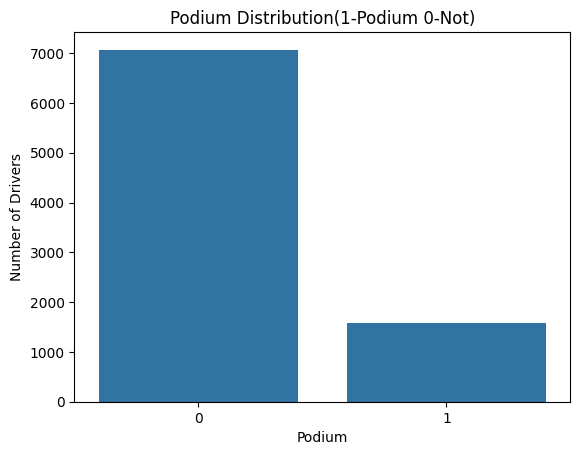

In [ ]:
sns.countplot(x="podium", data=file_final)
plt.title("Podium Distribution(1-Podium 0-Not)")
plt.xlabel("Podium")
plt.ylabel("Number of Drivers")
plt.show()

Histogram

Purpose:
To understand the distribution of drivers across different qualifying positions.

Insight:
The graph shows that lower qualifying position numbers occur more frequently, while fewer drivers appear in the later positions.

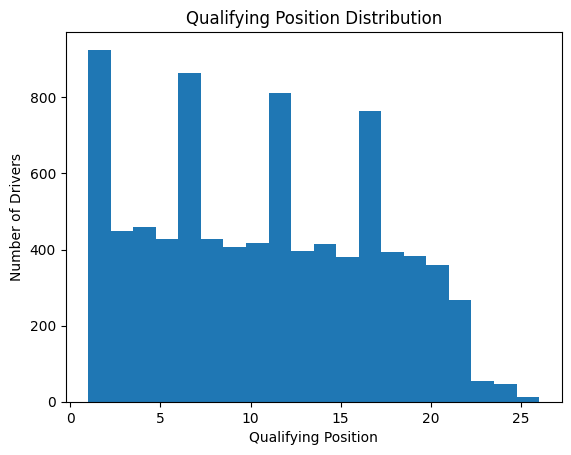

In [ ]:
plt.hist(file_final["qualifying_position"].dropna(), bins=20)

plt.title("Qualifying Position Distribution")
plt.xlabel("Qualifying Position")
plt.ylabel("Number of Drivers")
plt.show()

Histogram

Purpose:
To understand the distribution of drivers across different qualifying positions.

Insight:
The graph shows that lower qualifying position numbers occur more frequently, while fewer drivers appear in the later positions.

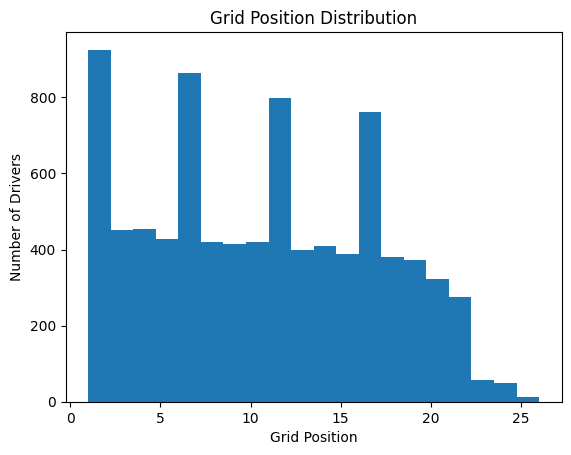

In [ ]:
plt.hist(file_final["grid_position"].dropna(), bins=20)

plt.title("Grid Position Distribution")
plt.xlabel("Grid Position")
plt.ylabel("Number of Drivers")
plt.show()

Histogram


Purpose:
To understand the distribution of drivers' average finishing positions over their last five races.

Insight:
Most drivers have an average finishing position between 3 and 13, while fewer drivers have higher average finishing-position numbers. Lower values indicate better recent performance.

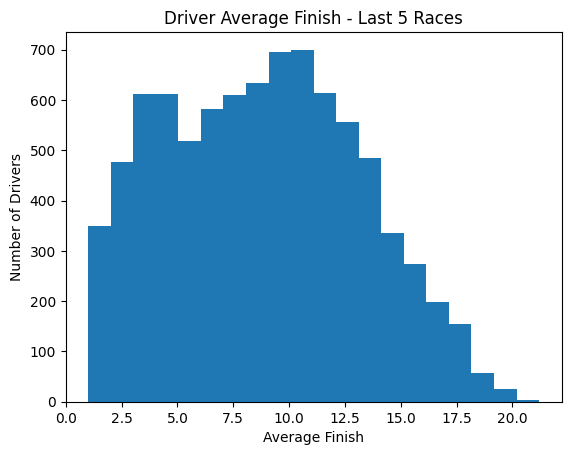

In [ ]:
plt.hist(file_final["driver_avg_finish_5"].dropna(), bins=20)

plt.title("Driver Average Finish - Last 5 Races")
plt.xlabel("Average Finish")
plt.ylabel("Number of Drivers")
plt.show()

BIVARIATE ANALYSIS

Scatter Plot

Purpose:
To examine the relationship between qualifying position and actual grid position.

Insight:
The graph shows a positive relationship: drivers with worse qualifying positions generally start further back on the grid. Some differences may be due to grid penalties.

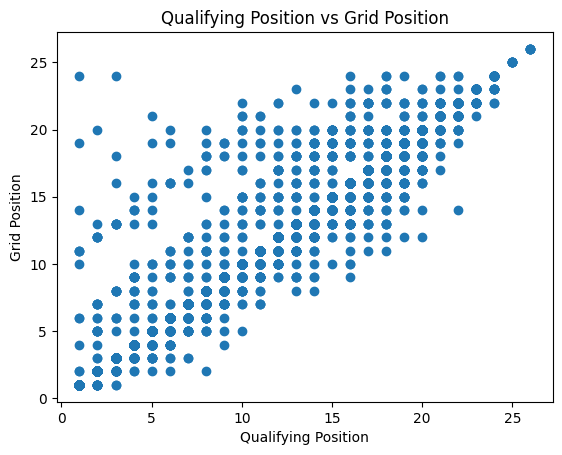

In [ ]:
plt.scatter(file_final["qualifying_position"], file_final["grid_position"])

plt.title("Qualifying Position vs Grid Position")
plt.xlabel("Qualifying Position")
plt.ylabel("Grid Position")
plt.show()

Scatter Plot

Purpose:
To examine the relationship between qualifying position and final race finishing position.

Insight:
Drivers with better qualifying positions generally tend to finish higher, but the spread of points shows that race results can vary considerably.

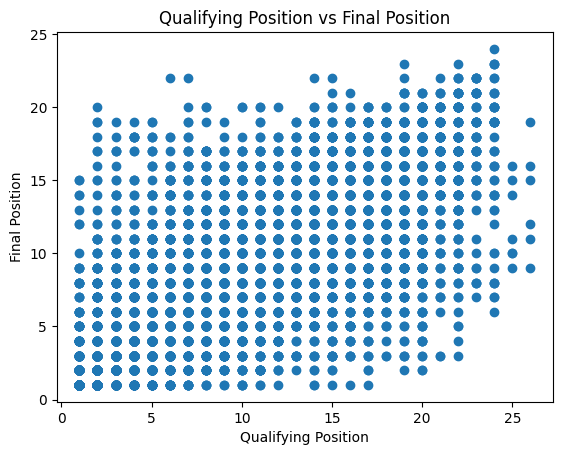

In [ ]:
plt.scatter(file_final["qualifying_position"], file_final["finish_position_numeric"])

plt.title("Qualifying Position vs Final Position")
plt.xlabel("Qualifying Position")
plt.ylabel("Final Position")
plt.show()

Box Plot

Purpose:
To compare the distribution of starting grid positions between race winners and non-winners.

Insight:
Winners generally start near the front of the grid, while non-winners have a wider range of starting positions. This suggests that grid position is an important feature for predicting F1 race winners.

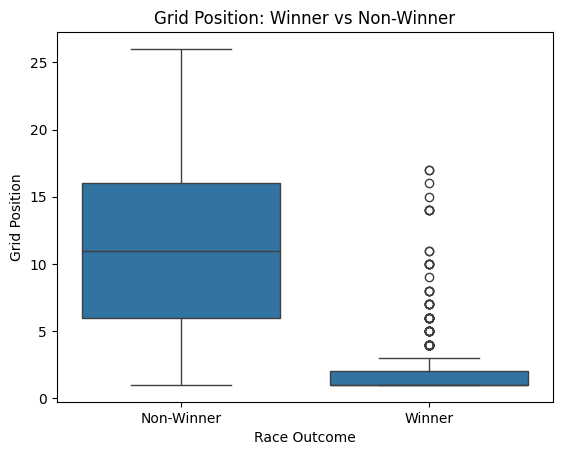

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("f1_final_cleaned_dataset50.csv")

df["winner"] = (df["finish_position_numeric"] == 1).astype(int)

sns.boxplot(x="winner", y="grid_position", data=df)

plt.title("Grid Position: Winner vs Non-Winner")
plt.xlabel("Race Outcome")
plt.ylabel("Grid Position")
plt.xticks([0, 1], ["Non-Winner", "Winner"])

plt.show()

Scatter Plot

Purpose:
To examine the relationship between starting grid position and final finishing position.

Insight:
Drivers starting closer to the front generally tend to finish in better positions, although race incidents and performance differences can affect the final result.

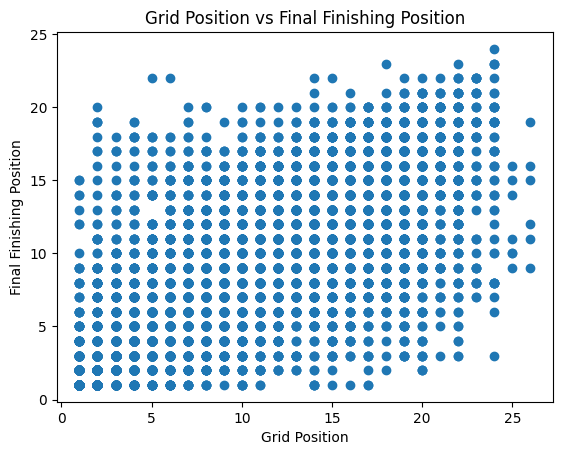

In [ ]:
plt.scatter(df["grid_position"], df["finish_position_numeric"])

plt.title("Grid Position vs Final Finishing Position")
plt.xlabel("Grid Position")
plt.ylabel("Final Finishing Position")

plt.show()

Line Plot

Purpose:
To examine how the probability of winning an F1 race changes with starting grid position.

Insight:
The graph shows that drivers starting near the front have a higher chance of winning, while the probability decreases sharply for drivers starting further back.

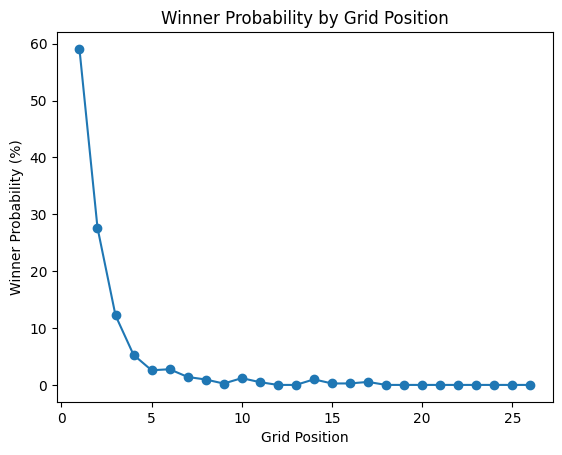

In [ ]:
winner_rate = df.groupby("grid_position")["winner"].mean() * 100

plt.plot(winner_rate.index, winner_rate.values, marker="o")

plt.title("Winner Probability by Grid Position")
plt.xlabel("Grid Position")
plt.ylabel("Winner Probability (%)")

plt.show()

MULTIVARIATE ANALYSIS

Correlation Heatmap

Purpose:
To identify relationships between numerical features and detect highly correlated variables in the F1 dataset.

Insight:
The heatmap shows that some driver performance features are strongly correlated. This helps identify related features before building the ML model.

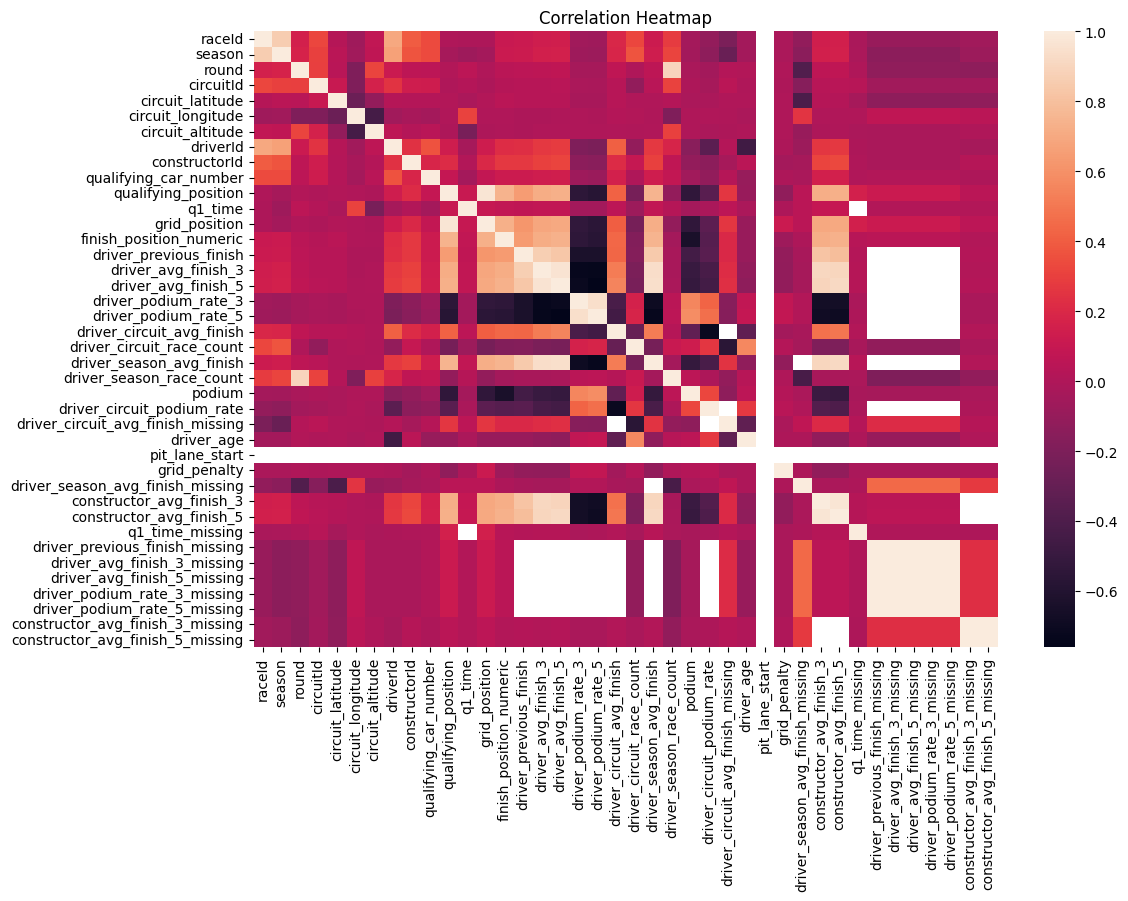

In [ ]:
correlation = file_final.corr(numeric_only=True)

plt.figure(figsize=(12, 8))

sns.heatmap(correlation)

plt.title("Correlation Heatmap")
plt.show()

# Machine Learning Model
now we will begin our process of creating the machine learning model to predict if a driver gets on the podium or misses out. The model we are going to be using is XG Boost also known as Extreme Gradient Boost.

In [ ]:
import pandas as pd

# Calculate numerical correlations
correlation_matrix = file_final.corr(numeric_only=True)

# Get correlations with the target variable 'podium'
podium_corr = correlation_matrix['podium'].sort_values(ascending=False)

# Display as a Dataframe
podium_corr_df = pd.DataFrame(podium_corr).reset_index()
podium_corr_df.columns = ['Feature', 'Correlation with Podium']

print("Correlation with Podium:")
display(podium_corr_df)

Correlation with Podium:


,Feature,Correlation with Podium
0,podium,1.000000
1,driver_podium_rate_5,0.582259
2,driver_podium_rate_3,0.557366
3,driver_circuit_podium_rate,0.322430
4,driver_circuit_race_count,0.129482
5,driver_age,0.055718
6,driver_season_race_count,0.051724
7,grid_penalty,0.016530
8,circuit_altitude,-0.001118
9,circuit_longitude,-0.002401


**Purpose:** To find out which features have the strongest correlation with the target variable and select features for prediction accordingly.

**Insights:** We gain the insights about which features have the highest positive and negative correlation.Here Driver podium rate,driver circuit podium rate and driver circuit race count all have high positive correlation while qualifying position grid position and driver season avg finsh have the highest negative correlation.

In [ ]:
predictors = [
    'driver_podium_rate_5',
    'driver_podium_rate_3',
    'driver_circuit_podium_rate',
    'driver_previous_finish',
    'driver_avg_finish_3',
    'driver_avg_finish_5',
    'driver_season_avg_finish',
    'driver_age',
    'driver_season_race_count',
    'driver_circuit_race_count',
    'constructor_avg_finish_3',
    'constructor_avg_finish_5',
    'grid_position',
    'qualifying_position',
    'grid_penalty',
    'circuit_altitude',
    'circuit_latitude',
    'circuit_longitude',
    'round',
    'season',
    'q1_time'
]

Here we seperate our predictors and only collect the features that we want to use and have sufficient correlation.

Lets define our ML model

In [ ]:
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

#Putting predictors as features
X = df[predictors]

# Target variable
y = df['podium']

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Create the XGBoost model
model = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    eval_metric='logloss',
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Evaluation of model
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Accuracy Percentage: ",(accuracy_score(y_test,y_pred))*100)

Accuracy: 0.8931870669745958
Accuracy Percentage:  89.31870669745959


# Model used: XGBoost
XG boost or extreme gradient boost is a type of ML model that makes predictions by learning patterns from data.For this particular use case the XGboost model learns the patterns between qualifying position,grid position,past driver performance and then it makes a prediction about the chance the driver has to get a podium in the race.

Purpose: To make the predictions and compare it with already avaialble data to check accuracy of our predictions.

Insights: We have made our predictions and compared them to the actual podium column and we can see that the model makes predictions which are 89% accurate.

In [ ]:
import joblib

joblib.dump(model, "f1_podium_model.pkl")
joblib.dump(predictors, "f1_features.pkl")

['f1_features.pkl']

This allows us to save our model for later use which we will need for our user input prediction system.

In [ ]:
import pandas as pd

# Load the original dataset
df = pd.read_csv("f1_final_cleaned_dataset50.csv")

# Extract the 2025 and 2026 seasons
df_2025_2026 = df[df["season"].isin([2025, 2026])]

# Save as a separate dataset
df_2025_2026.to_csv("f1_seasons_2025_2026.csv", index=False)

print(df_2025_2026.shape)

(616, 53)


In [ ]:
import pandas as pd
from xgboost import XGBClassifier

# Load dataset
df = pd.read_csv("/content/f1_seasons_2025_2026.csv")

# Load your trained model
import joblib

model = joblib.load("/content/f1_podium_model.pkl")

# Current driver list — edit to match your race lineup
current_drivers = [
    "Max Verstappen",
    "Lando Norris",
    "Oscar Piastri",
    "Charles Leclerc",
    "Lewis Hamilton",
    "George Russell",
    "Kimi Antonelli",
    "Fernando Alonso",
    "Lance Stroll",
    "Pierre Gasly",
    "Franco Colapinto",
    "Esteban Ocon",
    "Oliver Bearman",
    "Nico Hulkenberg",
    "Gabriel Bortoleto",
    "Carlos Sainz",
    "Alexander Albon",
    "Liam Lawson",
    "Isack Hadjar",
    "Sergio Perez",
    "Valtteri Bottas"
]

# Select track
tracks = sorted(df["circuit_name"].dropna().unique())

print("\nAvailable tracks:")
for t in tracks:
    print(t)

track = input("\nEnter track name: ").strip()

if track.lower() not in [t.lower() for t in tracks]:
    print("Track not found!")

else:
    selected_track = next(
        t for t in tracks if t.lower() == track.lower()
    )

    # Ask for season and round
    season = int(input("Enter race season (e.g. 2026): "))
    race_round = int(input("Enter race round number: "))

    # Collect qualifying positions
    data = []

    print("\nEnter qualifying positions:")

    for driver in current_drivers:
        while True:
            try:
                position = int(
                    input(f"{driver}: qualifying position = ")
                )

                if not 1 <= position <= len(current_drivers):
                    print("Enter a valid qualifying position.")
                    continue

                data.append({
                    "driver_name": driver,
                    "qualifying_position": position,
                    "grid_position": position,
                    "season": season,
                    "round": race_round
                })

                break

            except ValueError:
                print("Enter a whole number.")

    # Create prediction data
    prediction_df = pd.DataFrame(data)

    # Use the exact features expected by the model
    features = [
        "qualifying_position",
        "grid_position",
        "season",
        "round"
    ]

    # Check model feature compatibility
    if hasattr(model, "feature_names_in_"):
        features = list(model.feature_names_in_)

    missing = [c for c in features if c not in prediction_df.columns]

    if missing:
        print("\nCannot predict. Missing model features:", missing)

    else:
        X_new = prediction_df[features]

        # Get predicted podium probabilities
        probabilities = model.predict_proba(X_new)[:, 1]

        prediction_df["podium_probability"] = probabilities * 100

        # Rank drivers by model prediction
        prediction_df = prediction_df.sort_values(
            "podium_probability",
            ascending=False
        )

        # Display predicted podium
        print("\n================================")
        print("PREDICTED F1 PODIUM")
        print("Track:", selected_track)
        print("Season:", season)
        print("================================")

        for rank, (_, row) in enumerate(
            prediction_df.head(3).iterrows(), start=1
        ):
            print(
                f"{rank}. {row['driver_name']} - "
                f"{row['podium_probability']:.2f}% "
                "predicted podium probability"
            )

        print("\nFull model rankings:")
        print(
            prediction_df[
                ["driver_name", "qualifying_position",
                 "podium_probability"]
            ].to_string(index=False)
        )


Available tracks:
Albert Park Grand Prix Circuit
Autodromo Enzo e Dino Ferrari
Autodromo Nazionale di Monza
Autódromo Hermanos Rodríguez
Autódromo José Carlos Pace
Bahrain International Circuit
Baku City Circuit
Circuit Gilles Villeneuve
Circuit Park Zandvoort
Circuit de Barcelona-Catalunya
Circuit de Monaco
Circuit de Spa-Francorchamps
Circuit of the Americas
Hungaroring
Jeddah Corniche Circuit
Las Vegas Strip Street Circuit
Losail International Circuit
Marina Bay Street Circuit
Miami International Autodrome
Red Bull Ring
Shanghai International Circuit
Silverstone Circuit
Suzuka Circuit
Yas Marina Circuit

Enter track name: Baku City Circuit
Enter race season (e.g. 2026): 2025
Enter race round number: 7

Enter qualifying positions:
Max Verstappen: qualifying position = 3
Lando Norris: qualifying position = 6
Oscar Piastri: qualifying position = 5
Charles Leclerc: qualifying position = 8
Lewis Hamilton: qualifying position = 7
George Russell: qualifying position = 4
Kimi Antonelli: qu